# Random Forest — predicción de `opinion`

Obligatorio MLSI 2026 S2. Esta notebook contiene:

1. Carga de datos
2. Preprocesamiento (código común en `obl_utils.py`)
3. Validación y métricas
4. Random Forest: baseline y búsqueda de hiperparámetros
5. Análisis del modelo elegido
6. Submission y resultado en Kaggle

## 1. Carga de datos

In [1]:
import os
import urllib.request

# El código común (preprocesamiento y evaluación) está en obl_utils.py.
# En Colab no está el archivo, así que se descarga del repo.
if not os.path.exists('obl_utils.py'):
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/juanmareolon/OBL_ML/main/obl_utils.py', 'obl_utils.py')

import numpy as np
import pandas as pd
from obl_utils import *

# Carpetas de salida de esta notebook
CARPETA_RESULTADOS = 'resultados/Random_Forest'
CARPETA_KAGGLE = 'kaggle'
os.makedirs(CARPETA_RESULTADOS, exist_ok=True)
os.makedirs(CARPETA_KAGGLE, exist_ok=True)

train, test = cargar_datos()
X, y, X_test, ids_test = preparar_datos(train, test)

print('train:', train.shape, '| test:', test.shape)
print('X:', X.shape, '| X_test:', X_test.shape)
print('Balance de clases:', y.value_counts(normalize=True).round(3).to_dict())
X.head()

train: (3602, 14) | test: (1201, 14)
X: (3602, 15) | X_test: (1201, 15)
Balance de clases: {0: 0.506, 1: 0.494}


,budget_desconocido,log_budget,revenue_desconocido,log_revenue,log_roi,runtime,log_vote_count,log_popularity,anio,mes,sin_keywords,cant_keywords,main_genre_top10,original_language,director
0,0,18.064006,0,17.328879,0.391667,97.0,5.598422,2.657993,2002.0,10.0,0,8,Action,en,Betty Thomas
1,1,NaN,1,NaN,NaN,90.0,4.158883,1.767642,1992.0,5.0,0,4,Thriller,en,Tony Maylam
2,0,16.454568,0,15.446479,0.311093,90.0,4.234107,1.921864,2000.0,4.0,0,6,Drama,en,Davis Guggenheim
3,0,16.523561,0,18.384107,2.005155,96.0,6.928538,3.519225,2008.0,8.0,0,6,Drama,en,Woody Allen
4,0,19.336971,0,20.654943,1.555158,153.0,8.574329,4.604026,2009.0,7.0,0,7,Adventure,en,David Yates


## 2. Preprocesamiento

El código está en `obl_utils.py` y es el mismo para todas las notebooks de modelos, así la comparación entre modelos es justa. El motivo de cada decisión está detallado en `Arbol_Clasificacion.ipynb` (sección 2); acá va el resumen.

**Capa 1: limpieza fija (`limpiar`).** Transformaciones que no aprenden nada de los datos:

- `budget` y `revenue`: los 0 y los valores < 1000 pasan a NaN, y se agrega un indicador `*_desconocido`.
- `runtime`: los 0 pasan a NaN.
- `budget`, `revenue`, `vote_count` y `popularity`: `log1p`.
- Variables nuevas: `anio` y `mes` (de `release_date`), `log_roi`, `sin_keywords` y `cant_keywords`.
- Se descartan `status`, `original_title` y `overview`.

**Capa 2: pipeline de sklearn (`crear_preprocesador`).** Lo que *aprende* de los datos se ajusta solo con el train de cada fold:

- Numéricas: imputación por mediana + `StandardScaler`.
- `main_genre_top10` y `original_language`: one-hot (los idiomas con menos de 20 películas se agrupan).
- `director` no se usa (no mejoró el AUC del árbol).

**Qué cambia respecto de los otros modelos.** Nada: un Random Forest está hecho de árboles, así que, igual que el árbol, no depende de la escala de las variables (la estandarización y el `log1p` no le cambian los cortes). Se mantiene exactamente el mismo preprocesamiento para que la comparación con el árbol y la regresión logística sea justa.

## 3. Validación y métricas

**Validación: k-fold cross-validation estratificado** (`crear_cv()`), con 5 folds y `SEED = 42`. Todos los modelos usan exactamente los mismos folds.

- Cada película se usa para validar exactamente una vez, a diferencia del holdout (depende de una sola división al azar) y del repeated holdout (algunas películas se validan varias veces y otras ninguna).
- *Estratificado*: cada fold mantiene la proporción de clases (51/49).
- El preprocesador va dentro de un `Pipeline` junto al modelo (`crear_pipeline()`), así medianas, escalas y encodings se ajustan solo con el train de cada fold (sin *data leakage*).

**Métricas** (`evaluar()`): accuracy, precision, recall, F1 y AUC-ROC, con promedio y desvío entre folds. También se registra el AUC en train: si es mucho mayor que el de validación, el modelo está sobreajustando. La matriz de confusión se obtiene con `matriz_confusion()`, usando las predicciones de validación de cada fold.

La métrica principal para elegir es el **AUC**, porque es la que usa la competencia de Kaggle.

## 4. Random Forest

Un Random Forest entrena muchos árboles de decisión y promedia sus predicciones. Para que los árboles sean distintos entre sí usa dos fuentes de azar:

- Cada árbol se entrena con una muestra distinta de las películas, tomada al azar con reposición (*bootstrap*).
- En cada división, el árbol solo puede elegir entre un subconjunto al azar de las variables.

Cada árbol por separado sobreajusta, pero como se equivocan en cosas distintas, al promediarlos los errores se compensan. Así se conserva la flexibilidad del árbol (relaciones no lineales e interacciones) con mucho menos sobreajuste.

### 4.1 Baseline

Random Forest con los hiperparámetros por defecto de sklearn: 100 árboles sin límite de profundidad, hojas de 1 película y la raíz cuadrada de la cantidad de variables en cada división. Sirve como punto de partida para medir cuánto aportan los hiperparámetros.

In [2]:
from sklearn.ensemble import RandomForestClassifier

baseline = evaluar(RandomForestClassifier(random_state=SEED), X, y,
                   max_depth='sin límite', min_samples_leaf=1, max_features='sqrt')

COLS_TABLA = ['max_depth', 'min_samples_leaf', 'max_features',
              'auc', 'auc_std', 'auc_train', 'accuracy', 'precision', 'recall', 'f1']
pd.DataFrame([baseline])[COLS_TABLA].round(3)

,max_depth,min_samples_leaf,max_features,auc,auc_std,auc_train,accuracy,precision,recall,f1
0,sin límite,1,sqrt,0.816,0.013,1.0,0.738,0.75,0.705,0.726


Sin ajustar nada, el Random Forest alcanza un **AUC de 0,815 en validación con 1,00 en train**. El 1,00 en train se explica porque cada árbol crece sin límite y memoriza su muestra, igual que el árbol baseline. La diferencia es que acá la validación no se hunde (el árbol baseline daba 0,667): promediar 100 árboles distintos alcanza para igualar a la regresión logística (0,815) y superar al árbol ajustado (0,769).

En un Random Forest, un AUC alto en train es normal y no indica por sí solo un problema; lo que importa es el AUC de validación.

### 4.2 Búsqueda de hiperparámetros (grid search)

Se prueban **todas las combinaciones** de:

| Hiperparámetro | Valores | Qué controla |
|---|---|---|
| `max_depth` | 5, 10, 15, sin límite | Profundidad máxima de cada árbol. |
| `min_samples_leaf` | 1, 5, 10, 20 | Mínimo de películas en cada hoja. Evita reglas basadas en pocos casos. |
| `max_features` | sqrt, 0.5, todas | Cuántas variables puede probar cada división: la raíz cuadrada del total (5 de 27), la mitad o todas. Cuantas menos, más distintos son los árboles entre sí. |

Son 4 × 4 × 3 = **48 combinaciones**, cada una evaluada con la misma CV de 5 folds y con **300 árboles**. La cantidad de árboles no se incluye en la grilla porque no hay nada que elegir: agregar árboles no sobreajusta, solo tarda más (se verifica en la sección 4.5). La tabla completa se guarda en `resultados/Random_Forest/random_forest_grilla.csv`, y acá se muestran las 10 mejores.

La celda tarda unos minutos: entrena 48 × 5 bosques de 300 árboles.

In [3]:
import itertools

N_ARBOLES = 300

def crear_rf(max_depth, min_samples_leaf, max_features, n_estimators=N_ARBOLES):
    # Traduce los valores de la grilla ('sin límite', 'todas') a los que espera sklearn (None)
    return RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=None if max_depth == 'sin límite' else int(max_depth),
        min_samples_leaf=int(min_samples_leaf),
        max_features=None if max_features == 'todas' else max_features,
        random_state=SEED)

GRILLA = {
    'max_depth': [5, 10, 15, 'sin límite'],
    'min_samples_leaf': [1, 5, 10, 20],
    'max_features': ['sqrt', 0.5, 'todas'],
}

filas = []
for max_depth, min_samples_leaf, max_features in itertools.product(*GRILLA.values()):
    modelo = crear_rf(max_depth, min_samples_leaf, max_features)
    filas.append(evaluar(modelo, X, y, max_depth=max_depth,
                         min_samples_leaf=min_samples_leaf, max_features=max_features))

grilla = pd.DataFrame(filas).sort_values('auc', ascending=False).reset_index(drop=True)

grilla.to_csv(f'{CARPETA_RESULTADOS}/random_forest_grilla.csv', index=False)
print(f'{len(grilla)} combinaciones evaluadas')

48 combinaciones evaluadas


**Las 10 mejores combinaciones** (ordenadas por AUC de validación), comparadas con el baseline:

In [4]:
top10 = grilla.head(10)[COLS_TABLA].copy()
top10.index = range(1, 11)
top10.loc['baseline'] = pd.Series(baseline)[COLS_TABLA]
top10.round(3)

,max_depth,min_samples_leaf,max_features,auc,auc_std,auc_train,accuracy,precision,recall,f1
1,15,5,sqrt,0.825,0.011,0.960,0.743,0.761,0.698,0.728
2,15,1,sqrt,0.824,0.012,1.000,0.745,0.767,0.695,0.729
3,sin límite,5,sqrt,0.824,0.011,0.966,0.742,0.757,0.703,0.729
4,10,1,sqrt,0.824,0.013,0.971,0.743,0.768,0.686,0.725
5,10,1,0.5,0.823,0.011,0.979,0.741,0.765,0.686,0.723
6,10,5,sqrt,0.823,0.012,0.930,0.742,0.766,0.687,0.725
7,10,5,0.5,0.823,0.012,0.950,0.743,0.767,0.687,0.725
8,sin límite,10,sqrt,0.822,0.011,0.918,0.743,0.758,0.705,0.730
9,15,5,0.5,0.822,0.011,0.977,0.745,0.762,0.703,0.731
10,15,10,sqrt,0.822,0.011,0.917,0.744,0.760,0.704,0.731


### 4.3 Efecto de los hiperparámetros

- **Izquierda:** AUC en train y en validación según `max_depth`, con hojas de 1 película y `max_features = sqrt`. Con árboles poco profundos (`max_depth = 5`) el bosque rinde menos (0,801). Desde `max_depth = 10` la validación se estabiliza en 0,82 aunque el train llegue a 1,00. Es la diferencia clave con el árbol solo, donde la validación caía al aumentar la profundidad (de 0,753 a 0,667): en el bosque, dejar crecer los árboles no perjudica.
- **Derecha:** AUC de validación según `min_samples_leaf` para cada `max_features`, con `max_depth = 15`. En general, probar pocas variables por división (`sqrt`) da los mejores resultados y probar todas da los peores, porque los árboles quedan más parecidos entre sí. Las hojas de 20 películas rinden algo menos. De todos modos, las diferencias son chicas (el eje va de 0,812 a 0,824) y menores al desvío entre folds (0,011).

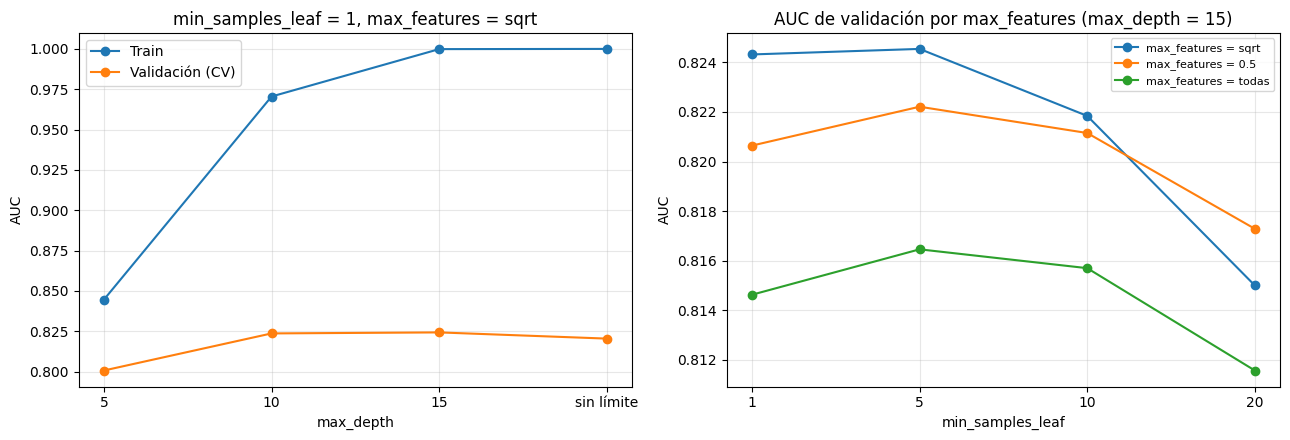

In [5]:
import matplotlib.pyplot as plt

g = grilla.assign(max_depth=grilla['max_depth'].astype(str), max_features=grilla['max_features'].astype(str))
orden = [str(d) for d in GRILLA['max_depth']]
g['max_depth'] = pd.Categorical(g['max_depth'], categories=orden, ordered=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

hoja1 = g[(g['min_samples_leaf'] == 1) & (g['max_features'] == 'sqrt')].sort_values('max_depth')
axes[0].plot(hoja1['max_depth'].astype(str), hoja1['auc_train'], 'o-', label='Train')
axes[0].plot(hoja1['max_depth'].astype(str), hoja1['auc'], 'o-', label='Validación (CV)')
axes[0].set_title('min_samples_leaf = 1, max_features = sqrt')
axes[0].set_xlabel('max_depth')
axes[0].legend()

profundo = g[g['max_depth'] == '15']
for max_features in GRILLA['max_features']:
    sub = profundo[profundo['max_features'] == str(max_features)].sort_values('min_samples_leaf')
    axes[1].plot(sub['min_samples_leaf'].astype(str), sub['auc'], 'o-', label=f'max_features = {max_features}')
axes[1].set_title('AUC de validación por max_features (max_depth = 15)')
axes[1].set_xlabel('min_samples_leaf')
axes[1].legend(fontsize=8)

for ax in axes:
    ax.set_ylabel('AUC')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 4.4 Mejor configuración

Se elige la combinación con **mayor AUC de validación**. Si hay otras dentro de un desvío estándar, se muestran para considerar la más simple (menos profunda o con hojas más grandes) y la de menor distancia entre train y validación.

In [6]:
mejor = grilla.iloc[0]
print('Mejor Random Forest:')
print(f"  max_depth={mejor['max_depth']}, min_samples_leaf={mejor['min_samples_leaf']}, max_features={mejor['max_features']}")
print(f"  AUC validación = {mejor['auc']:.3f} ± {mejor['auc_std']:.3f}")
print(f"  AUC train      = {mejor['auc_train']:.3f}  (diferencia {mejor['auc_train'] - mejor['auc']:.3f})")
print(f"  Mejora sobre el baseline: +{mejor['auc'] - baseline['auc']:.3f} de AUC")

empatadas = grilla[grilla['auc'] >= mejor['auc'] - mejor['auc_std']]
print(f"\nCombinaciones dentro de un desvío del mejor: {len(empatadas)} (se muestran las 10 primeras)")
empatadas.head(10)[COLS_TABLA].assign(diferencia_train_val=empatadas['auc_train'].head(10) - empatadas['auc'].head(10)).round(3)

Mejor Random Forest:
  max_depth=15, min_samples_leaf=5, max_features=sqrt
  AUC validación = 0.825 ± 0.011
  AUC train      = 0.960  (diferencia 0.136)
  Mejora sobre el baseline: +0.009 de AUC

Combinaciones dentro de un desvío del mejor: 32 (se muestran las 10 primeras)


,max_depth,min_samples_leaf,max_features,auc,auc_std,auc_train,accuracy,precision,recall,f1,diferencia_train_val
0,15,5,sqrt,0.825,0.011,0.960,0.743,0.761,0.698,0.728,0.136
1,15,1,sqrt,0.824,0.012,1.000,0.745,0.767,0.695,0.729,0.176
2,sin límite,5,sqrt,0.824,0.011,0.966,0.742,0.757,0.703,0.729,0.142
3,10,1,sqrt,0.824,0.013,0.971,0.743,0.768,0.686,0.725,0.147
4,10,1,0.5,0.823,0.011,0.979,0.741,0.765,0.686,0.723,0.156
5,10,5,sqrt,0.823,0.012,0.930,0.742,0.766,0.687,0.725,0.107
6,10,5,0.5,0.823,0.012,0.950,0.743,0.767,0.687,0.725,0.127
7,sin límite,10,sqrt,0.822,0.011,0.918,0.743,0.758,0.705,0.730,0.096
8,15,5,0.5,0.822,0.011,0.977,0.745,0.762,0.703,0.731,0.155
9,15,10,sqrt,0.822,0.011,0.917,0.744,0.760,0.704,0.731,0.095


**Elección:** `max_depth=15`, `min_samples_leaf=5`, `max_features=sqrt`, con 300 árboles. Tiene el mayor AUC de validación (0,824 ± 0,011). La mejora sobre el baseline es de solo 0,009, menor al desvío entre folds: 32 de las 48 combinaciones quedan dentro de un desvío de la mejor, todas con `max_depth` de 10 o más. Igual que con la regresión logística, el ajuste aporta poco; lo que hace la diferencia es el modelo en sí.

La diferencia entre train y validación (0,136) es alta comparada con la del árbol elegido (0,044) o la de la regresión logística (0,005), pero en un Random Forest no se interpreta igual: cada árbol memoriza buena parte de su muestra y lo que generaliza es el promedio. Entre las combinaciones empatadas, las de hojas de 10 películas tienen una diferencia menor (0,095) con prácticamente el mismo AUC (0,822) y serían una elección igual de válida; se mantiene la de mayor AUC, como en los otros modelos.

### 4.5 Cantidad de árboles

Con la configuración elegida, se evalúa el mismo bosque con distintas cantidades de árboles para verificar que 300 son suficientes.

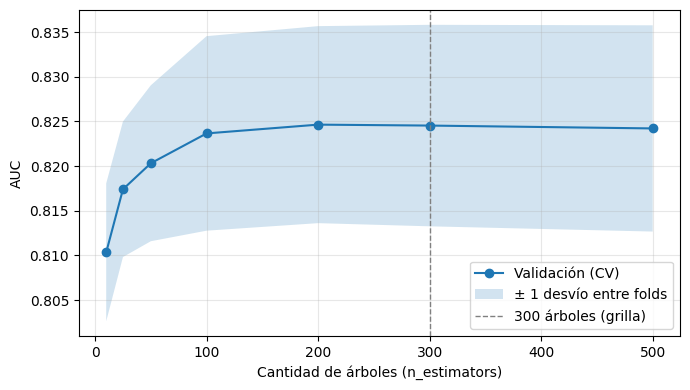

,n_arboles,auc,auc_std,auc_train
0,10,0.810,0.008,0.942
1,25,0.817,0.008,0.952
2,50,0.820,0.009,0.957
3,100,0.824,0.011,0.958
4,200,0.825,0.011,0.960
5,300,0.825,0.011,0.960
6,500,0.824,0.012,0.960


In [7]:
filas_arboles = []
for n_arboles in [10, 25, 50, 100, 200, 300, 500]:
    modelo = crear_rf(mejor['max_depth'], mejor['min_samples_leaf'], mejor['max_features'], n_estimators=n_arboles)
    filas_arboles.append(evaluar(modelo, X, y, n_arboles=n_arboles))
arboles = pd.DataFrame(filas_arboles)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(arboles['n_arboles'], arboles['auc'], 'o-', label='Validación (CV)')
ax.fill_between(arboles['n_arboles'], arboles['auc'] - arboles['auc_std'], arboles['auc'] + arboles['auc_std'],
                alpha=0.2, label='± 1 desvío entre folds')
ax.axvline(N_ARBOLES, color='gray', linestyle='--', linewidth=1, label=f'{N_ARBOLES} árboles (grilla)')
ax.set_xlabel('Cantidad de árboles (n_estimators)')
ax.set_ylabel('AUC')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

arboles[['n_arboles', 'auc', 'auc_std', 'auc_train']].round(3)

Con pocos árboles el resultado es peor (0,810 con 10 árboles). A partir de 100 árboles el AUC se estabiliza en 0,824, y agregar más no lo mejora ni lo empeora (0,824 con 500). Los 300 de la grilla están dentro de la zona estable, así que no hace falta ajustar este hiperparámetro: más árboles solo aumentarían el tiempo de entrenamiento.

## 5. Análisis del modelo elegido

Se reconstruye el mejor Random Forest de la grilla y se analiza: matriz de confusión (con las predicciones de validación de la CV) e importancia de variables, comparada con la del árbol.

In [8]:
params_mejor = {
    'max_depth': mejor['max_depth'],
    'min_samples_leaf': int(mejor['min_samples_leaf']),
    'max_features': mejor['max_features'],
}
mejor_rf = crear_rf(**params_mejor)
mejor_rf

RandomForestClassifier(max_depth=15, min_samples_leaf=5, n_estimators=300,
                       random_state=42)

### 5.1 Matriz de confusión

Cada película se predice con el modelo del fold en el que quedó en validación (o sea, con un modelo que no la vio al entrenar). Se usa el umbral por defecto de 0,5 sobre la probabilidad.

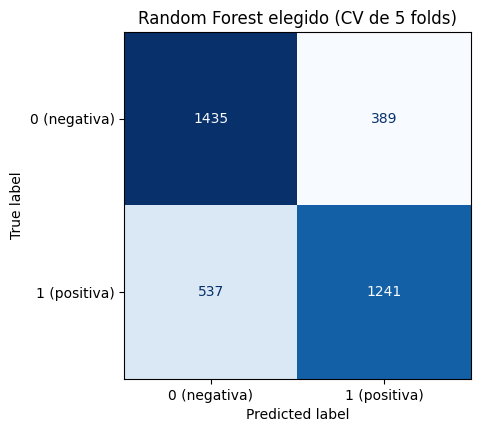

Verdaderos negativos: 1435  | Falsos positivos: 389
Falsos negativos:     537  | Verdaderos positivos: 1241
De las películas con opinión positiva, detecta el 70% (recall)
De las que predice como positivas, acierta el 76% (precision)


In [9]:
fig, ax = plt.subplots(figsize=(5, 4.5))
cm = matriz_confusion(mejor_rf, X, y, titulo='Random Forest elegido (CV de 5 folds)', ax=ax)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'Verdaderos negativos: {tn}  | Falsos positivos: {fp}')
print(f'Falsos negativos:     {fn}  | Verdaderos positivos: {tp}')
print(f'De las películas con opinión positiva, detecta el {tp / (tp + fn):.0%} (recall)')
print(f'De las que predice como positivas, acierta el {tp / (tp + fp):.0%} (precision)')

Clasifica bien el 79% de las películas con opinión negativa y el 70% de las positivas. Comparado con la regresión logística (77% y 72%), acierta más en las negativas y menos en las positivas, y la accuracy es prácticamente la misma (0,743 contra 0,744). La ventaja del Random Forest está en el AUC (0,824 contra 0,815), es decir, en cómo ordena las películas por probabilidad, y no en la clasificación con el umbral de 0,5. Igual que los otros modelos, se equivoca más con las positivas (538 falsos negativos contra 388 falsos positivos).

### 5.2 Importancia de variables

Se entrena el Random Forest con todo el train. La importancia de cada variable es el promedio, entre los 300 árboles, de cuánto reduce la impureza (`feature_importances_`). Para comparar, se entrena también el árbol elegido en `Arbol_Clasificacion.ipynb` (`max_depth=8`, `min_samples_leaf=50`) y se muestran las dos importancias juntas.

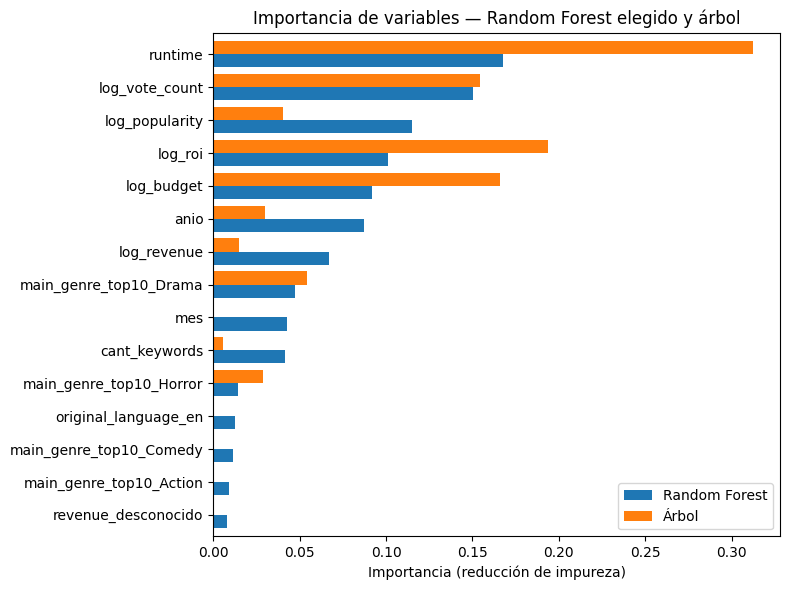

Variables con importancia mayor a 0: Random Forest 27 de 27, árbol 10 de 27


,Random Forest,Árbol
runtime,0.168,0.312
log_vote_count,0.150,0.154
log_popularity,0.115,0.040
log_roi,0.101,0.194
log_budget,0.092,0.166
anio,0.087,0.030
log_revenue,0.067,0.015
main_genre_top10_Drama,0.047,0.054
mes,0.043,0.000
cant_keywords,0.042,0.006


In [10]:
from sklearn.tree import DecisionTreeClassifier

pipe_mejor = entrenar(mejor_rf, X, y)
nombres = pipe_mejor.named_steps['prep'].get_feature_names_out()
importancias = (pd.Series(pipe_mejor.named_steps['modelo'].feature_importances_, index=nombres)
                .sort_values(ascending=False))

# Árbol elegido en Arbol_Clasificacion.ipynb, para comparar
pipe_arbol = entrenar(DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, criterion='gini',
                                             random_state=SEED), X, y)
importancias_arbol = pd.Series(pipe_arbol.named_steps['modelo'].feature_importances_, index=nombres)

comparacion = pd.DataFrame({'Random Forest': importancias, 'Árbol': importancias_arbol}).loc[importancias.index].head(15)

fig, ax = plt.subplots(figsize=(8, 6))
comparacion.iloc[::-1].plot.barh(ax=ax, width=0.8)
ax.set_title('Importancia de variables — Random Forest elegido y árbol')
ax.set_xlabel('Importancia (reducción de impureza)')
plt.tight_layout()
plt.show()

print(f'Variables con importancia mayor a 0: Random Forest {(importancias > 0).sum()} de {len(importancias)}, '
      f'árbol {(importancias_arbol > 0).sum()} de {len(importancias_arbol)}')
comparacion.head(10).round(3)

**Lectura:**

- Las variables más importantes son las mismas que en el árbol: duración, cantidad de votos, ROI y presupuesto. Coincide también con la regresión logística, donde los votos y la duración tenían los coeficientes positivos más grandes.
- La importancia está **más repartida**. El árbol usaba solo 10 de las 27 variables y concentraba el 31% en la duración; el Random Forest usa las 27 y la duración baja al 17%. Como cada división solo puede elegir entre unas pocas variables al azar, las que en el árbol casi no aparecían (popularidad, año, recaudación, mes) acá sí aportan.
- A diferencia de los coeficientes de la regresión logística, la importancia no tiene signo: dice cuánto se usa una variable, no si sube o baja la probabilidad de opinión positiva.
- Esta medida favorece a las variables numéricas, que ofrecen muchos cortes posibles, frente a las binarias (géneros, idiomas, indicadores). Por eso el género Horror, que en la regresión logística tenía el segundo coeficiente más grande, acá aparece con poca importancia.

## 6. Submission y resultado en Kaggle

Se entrena el Random Forest elegido con **todo** el train y se guardan las **probabilidades** de la clase 1 para las 1201 películas del test (no clases 0/1, porque la métrica de la competencia es AUC). El archivo queda en `kaggle/submission_random_forest.csv`.

In [11]:
sub = generar_submission(mejor_rf, X, y, X_test, ids_test, f'{CARPETA_KAGGLE}/submission_random_forest.csv')

# Chequeos: 1201 filas, sin NaN y probabilidades (no solo 0/1)
assert len(sub) == len(X_test) and sub['opinion'].notna().all()
print(f"Probabilidades entre {sub['opinion'].min():.3f} y {sub['opinion'].max():.3f}, "
      f"{sub['opinion'].nunique()} valores distintos")
sub.head()

Guardado kaggle/submission_random_forest.csv (1201 filas)
Probabilidades entre 0.070 y 0.981, 1201 valores distintos


,id,opinion
0,0,0.912926
1,1,0.495230
2,2,0.838043
3,3,0.896513
4,4,0.692646


### Resultado en Kaggle

*Public Score* obtenido al subir `kaggle/submission_random_forest.csv`. La fila se guarda en `resultados/Random_Forest/random_forest_final.csv` para la tabla comparativa entre modelos.



In [13]:
auc_kaggle = 0.84439  

resultado_final = {
    'modelo': 'Random Forest',
    'hiperparametros': (f"n_estimators={N_ARBOLES}, max_depth={params_mejor['max_depth']}, "
                        f"min_samples_leaf={params_mejor['min_samples_leaf']}, max_features={params_mejor['max_features']}"),
    'auc_cv': mejor['auc'], 'auc_cv_std': mejor['auc_std'], 'auc_train': mejor['auc_train'],
    'accuracy': mejor['accuracy'], 'precision': mejor['precision'], 'recall': mejor['recall'], 'f1': mejor['f1'],
    'auc_kaggle': auc_kaggle,
}
pd.DataFrame([resultado_final]).to_csv(f'{CARPETA_RESULTADOS}/random_forest_final.csv', index=False)
pd.DataFrame([resultado_final]).round(3)

,modelo,hiperparametros,auc_cv,auc_cv_std,auc_train,accuracy,precision,recall,f1,auc_kaggle
0,Random Forest,"n_estimators=300, max_depth=15, min_samples_le...",0.825,0.011,0.96,0.743,0.761,0.698,0.728,0.844


Interpretación: Como era de esperar, el resultado obtenido en Kaggle fue levemente superior al de los dos modelos anteriores. Sin embargo, se observa una mayor varianza con respecto al AUC de entrenamiento (auc_train). A partir del AUC obtenido en Kaggle (auc_kaggle), podemos inferir que este modelo presenta un mejor desempeño que los modelos de Regresión Logística y Árbol de Decisión.